# 📘 9.4 Boundary Value Problems
###

This notebook introduces ODEs whose solutions are constrained not simply by an initial condition, but rather by a condition at two or more points, sudh as a known condition at a boundary.


---

### 🎯 Learning Objectives
> By the end of this notebook, you should be able to:
>
> * Recognise the difference between an **initial** and a **boundary value** problem;
> * Reduce a boundary value problem to an initial value problem by guessing unknown initial condition(s);
> * Formulate sensitivity equations for the solution as a function of guessed initial conditions;
> * Combine initial value and sensitivity equations to construct the framework for an iterative **shooting method** approach to solving boundary value problems.

## 📂 9.4.0 How to use this notebook

This notebook introduces the nature of boundary value problems and the concepts behind the shooting method solution approach.

> ### 🧭 Theory preface
> Given an ODE, you should be able to formulate the equations for the sensitivity terms, and the updates need to propagate initial values of the dependent varibales of the ODE and sensitivity terms from an initial condition, at $a$, to a target state at $b$.
>
> As with stability analysis, and implicit methods, this is procedural approach that you should be able to apply.


## 📂 9.4.1 Initial Value vs Boundary Value Problems

---

So far, we have considered ODEs that are initial value problems, i.e.

> ### 📖 Definition
> **Initial Value Problem:** is one in which all required conditions for the solution are represented by one value of the independent variable, at a single point, from which the solution can be propagated along a **unique trajectory**.

For example,
$$ \frac{\mbox{d}y}{\mbox{d}t} = -\lambda y + At,$$

can be solved if we know $y$ at a given value of $t$, commonly, but not necessarily, at time $t=0$.

A boundary value problem, is one where there are conditions at two or more points that must both be satisfied,

> ### 📖 Definition
> **Boundary Value Problem:** consists of a differential equation plus conditions given at two or more distinct points, typically the endpoints of an interval, which act to constrain the solution.
>
> Depending on these *boundary values*, there may be, one, many, or no solutions that statisfy the boundary conditions.

In engineering we commonly encounter *boundary value problems* in the case of a steady state solution to a system, where we set the a force at one end of a beam and fix the displacement at the other and want to determine the displacement along it's length.


| **Feature** | **Initial Value Problem (IVP)** | **Boundary Value Problem (BVP)** |
|-------------|---------------------------------|----------------------------------|
| Where conditions are given | One point \(x_0\) | Two or more points |
| Typical use | Time evolution | Spatial steady‑state |
| Existence & uniqueness | Guaranteed (linear, continuous coefficients) | Not guaranteed |
| Numerical approach | March forward from initial point | Iterate to satisfy all boundary constraints |
| Example | $y(0)=y_0; y'(0)=v_0$ | $y(a)=\alpha; y(b)=\beta$ |

Consider the example ODE,

$$y''+4y = 0$$

Recall, from [Notebook 7.5](https://colab.research.google.com/drive/14GQD1Xu_PAIcOjUHYVX9WjaQVqnFxrKf?usp=playground), we can solve a higher ODE if we let

$$ y_1 = y, y_2 = y'$$

and consider 1st order ODEs for $y_1$ and $y_2$ as

$$\frac{\mbox{d}}{\mbox{d}t}\begin{bmatrix}y_1\\ y_2\end{bmatrix} = \begin{bmatrix}y'\\ y''\end{bmatrix}$$

where by definition $y'=y_2$ and from the ODE $y'' = -4y$, i.e.

$$\frac{\mbox{d}}{\mbox{d}t}\begin{bmatrix}y_1\\ y_2\end{bmatrix} = \begin{bmatrix}y_2\\ -4y_1\end{bmatrix}$$

An explicit Euler update to each terms is given by

\begin{align}
y_{1,n+1} &= y_{1,n} + y'_{1,n}h=y_{1,n} + y_{2,n}h,\\
y_{2,n+1} &= y_{2,n} + y'_{2,n}h=y_{2,n} - 4y_{1,n}h,\\
\end{align}

where we can update both $y_{1,2}$ if we know both at one point in time, e.g. $y(0)$ and $y'(0)$.


### 💻 Explicit Euler Method Implementation

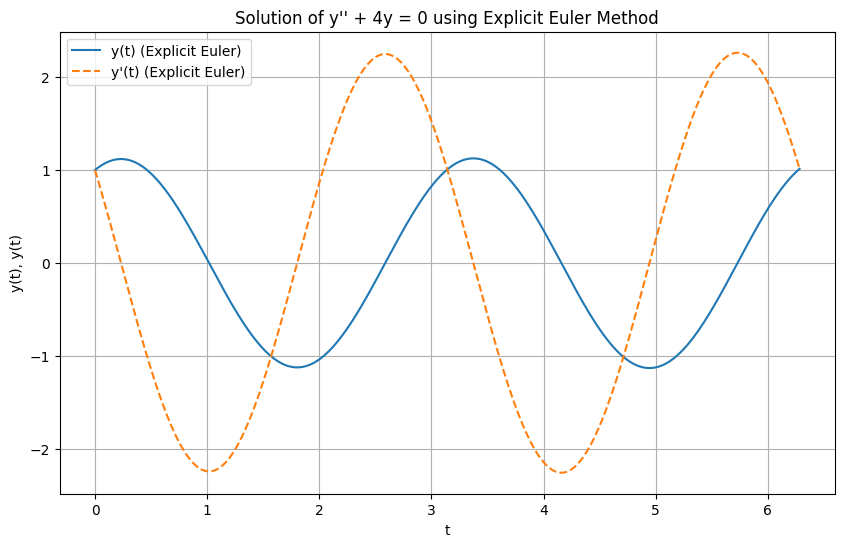

In [ ]:
# @title
y1_init = 1 # @param {"type":"number","placeholder":"0"}
y2_init = 1 # @param {"type":"number","placeholder":"0"}
step_size = 0.001 # @param {"type":"number","placeholder":"0.01"}
import numpy as np
import matplotlib.pyplot as plt

# Define the ODE system
def explicit_euler_step(y1, y2, h):
    dy1_dt = y2
    dy2_dt = -4 * y1
    y1_new = y1 + dy1_dt * h
    y2_new = y2 + dy2_dt * h
    return y1_new, y2_new

# Parameters
h = step_size  # Step size
t_start = 0.0
t_end = 2 * np.pi  # Simulate for one full cycle

# Initial conditions (example values)
y1_0 = y1_init
y2_0 = y2_init

# Number of steps
n_steps = int((t_end - t_start) / h)

# Initialize arrays to store results
t_values = np.linspace(t_start, t_end, n_steps + 1)
y1_values = np.zeros(n_steps + 1)
y2_values = np.zeros(n_steps + 1)

y1_values[0] = y1_0
y2_values[0] = y2_0

# Numerical integration using Explicit Euler
for i in range(n_steps):
    y1_values[i+1], y2_values[i+1] = explicit_euler_step(y1_values[i], y2_values[i], h)

# Plot the results
fig = plt.figure(figsize=(10, 6))
plt.plot(t_values, y1_values, label='y(t) (Explicit Euler)')
plt.plot(t_values, y2_values, label="y'(t) (Explicit Euler)", linestyle='--')

# Compare with analytical solution (y(t) = A sin(2t) + B cos(2t))
# For y(0)=0 and y'(0)=2, the analytical solution is y(t) = sin(2t)
#analytical_y = np.sin(2 * t_values)
#plt.plot(t_values, analytical_y, label='Analytical y(t) (sin(2t))', linestyle=':')

plt.title("Solution of y'' + 4y = 0 using Explicit Euler Method")
plt.xlabel('t')
plt.ylabel('y(t), y''(t)')
plt.legend()
plt.grid(True)
plt.show()


---
*What if we don't know the initial $y'(0)$ but we know $y(0)$ and $y(\beta)$?*

Now we have a boundary value problem to solve.

---

## 📂 9.4.2 The Shooting Method

---

One method that can be used to solve a **boundary value problem** is to use the same method we did for an *initial value problem*.

Yes! you read that correctly! We will use the same method! - with a *minor* change.

In order to solve this like an *initial value problem*, we need to assume a value for the missing initial condition. E.g. if we know $y_1(0)$, we need to take a guess at $y_2(0)$. Once we do we can propagate $y_1$ and $y_2$ from $t=0 → \beta$ and see if we hit our boundary condition of $y(\beta)$.

The reason for the terms *shooting method*, is that this approach is analogous to aiming a cannon at our target - adjusting our initial condition until we hit the bullseye.

The code below considers a range of shots, all of which satisfy the initial condition $y(0)=1$, but varying in their initial value of $y_2(0)$, the second plot showing how close each solution got to a target boundary value of $y(6)=0.6$.

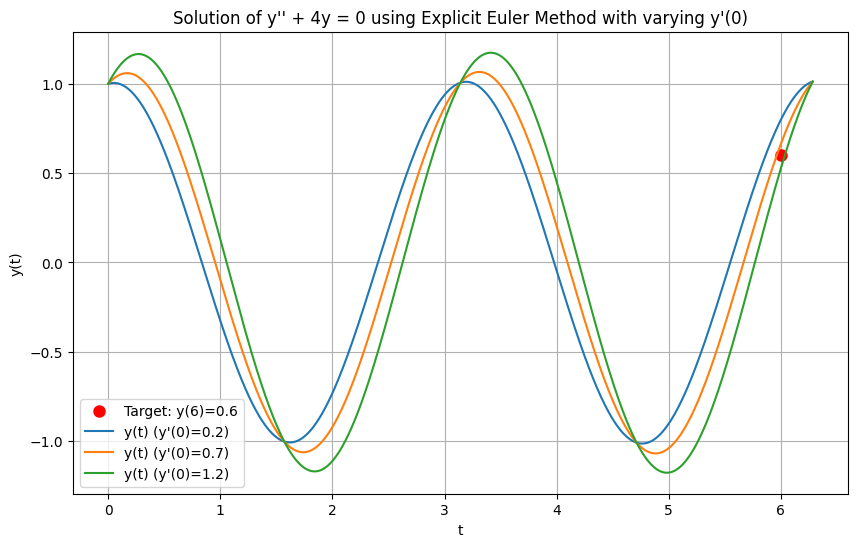

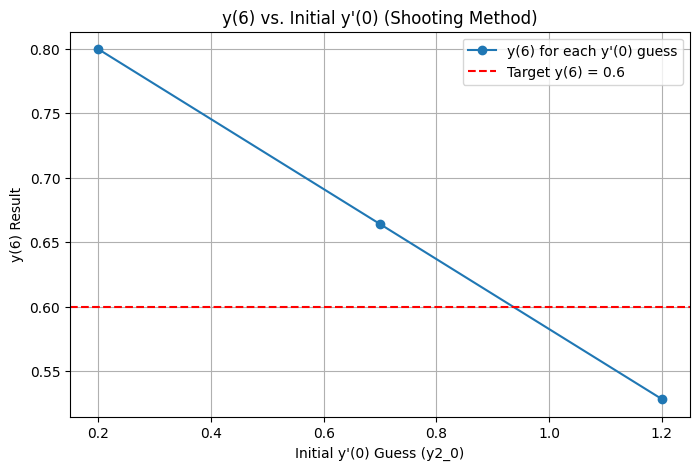

In [ ]:
# @title Shooting - target y(6) = 0.6
y1_init = 1
y2_init_array = [0.2, 0.7, 1.2]
step_size = 0.001 # @param {"type":"number","placeholder":"0.01"}
import numpy as np
import matplotlib.pyplot as plt

# Define the ODE system
def explicit_euler_step(y1, y2, h):
    dy1_dt = y2
    dy2_dt = -4 * y1
    y1_new = y1 + dy1_dt * h
    y2_new = y2 + dy2_dt * h
    return y1_new, y2_new

# Parameters
h = step_size  # Step size
t_start = 0.0
t_end = 2 * np.pi  # Simulate for one full cycle

# Number of steps
n_steps = int((t_end - t_start) / h)

# Prepare to store results for the second plot
y2_guesses = []
y1_at_t6_results = []
target_t = 6.0

# Initialize plot for trajectories
fig_trajectories = plt.figure(figsize=(10, 6))
plt.plot([target_t], [0.6],'ro', markersize=8, label='Target: y(6)=0.6')

# Iterate through different initial conditions for y'(0)
for y2_val in y2_init_array:
    # Initial conditions
    y1_0 = y1_init
    y2_0 = y2_val

    # Initialize arrays to store results for current y2_0
    t_values = np.linspace(t_start, t_end, n_steps + 1)
    y1_values = np.zeros(n_steps + 1)
    y2_values = np.zeros(n_steps + 1)

    y1_values[0] = y1_0
    y2_values[0] = y2_0

    # Numerical integration using Explicit Euler
    for i in range(n_steps):
        y1_values[i+1], y2_values[i+1] = explicit_euler_step(y1_values[i], y2_values[i], h)

    # Plot the results for the current y2_val on the first figure
    plt.plot(t_values, y1_values, label=f"y(t) (y'(0)={y2_val})")

    # Store y1(t=6) for the second plot
    idx_t6 = np.argmin(np.abs(t_values - target_t))
    y1_at_t6_results.append(y1_values[idx_t6])
    y2_guesses.append(y2_val)

# Customize and show the trajectories plot
plt.title("Solution of y'' + 4y = 0 using Explicit Euler Method with varying y'(0)")
plt.xlabel('t')
plt.ylabel('y(t)')
plt.legend()
plt.grid(True)
plt.show()

# Create the second plot for shooting results at t=6
fig_shooting = plt.figure(figsize=(8, 5))
plt.plot(y2_guesses, y1_at_t6_results, 'o-', label='y(6) for each y\'(0) guess')
plt.axhline(y=0.6, color='r', linestyle='--', label='Target y(6) = 0.6')
plt.title("y(6) vs. Initial y'(0) (Shooting Method)")
plt.xlabel("Initial y'(0) Guess (y2_0)")
plt.ylabel("y(6) Result")
plt.legend()
plt.grid(True)
plt.show()


These guesses are pretty good, but we don't want to have to be taking pot shots at random. Well, we don't have to. Just as a spotter might observer that the shot missed high or low of the target, we can adjust the trajectory of our next shot using a root finding approach.

Focusing on the second plot, we can use Newton's methods to estimate where the blue line crosses our target (red-line), and use that to improve our guess.

To explain the use of Newton's method in this context it helps to first characterise the shooting methods as follows.



### 🔹 Setting Up the Shooting Method and Shooting Function

The general **shooting method** between bounds (a,b) is as follows
1. Set-up the update equation for an initial value problem (IVP);
2. Parameterise the unknown initial value(s)
    e.g. We know
       
   $$y_1(a) = y(a) = \alpha.$$

    Let the unknown initial slope be
     $$ y_2(a) = s,$$

    such that you can solve the initial value problem for $s$, from $x=a$ to $x=b$.

3. Define the shooting function

    Let $y_1(b; s)$ be the solution of the IVP with initial data
     $$ y_1(a) = \alpha,\quad y_2(a) = s.$$
    Define the shooting function
     $$ F(s) = y_1(b; s) - \beta,$$
    where $\beta$ is the target solution at $b$, and the BVP is satisfied when
     $$ F(s) = 0.$$

### 🔹 Finding the Root of the Shooting Function

Having the shooting function $F(s)$, the task is now to determine $s$ such that $F(s)=0$, i.e. we need to find the root of the Shooting function.

From Newton's method we can iterative solve for the root as follows

$$s_{k+1} = s_k - \frac{F(s_k)}{F'(s_k)}.\tag{9.21}$$

To estimate $s$ we need $F'(s)$.

\begin{align}\frac{\partial F}{\partial s} &= \frac{\partial}{\partial s}\left(y_1(b;s)-\beta\right)\\
\frac{\partial F}{\partial s} &=\frac{\partial y_1(b;s)}{\partial s}.
\end{align}

This is the sensitivity of $y_1(b; s)$ with respect to $s$.


The $z_{1,2}$ be sensitivity of the solution of $y_1$ and $y_2$ at some time $t$, to the initial $s$,

$$z_1(t;s) = \frac{\partial y_1(t; s)}{\partial s}, z_2(t;s) = \frac{\partial y_2(t; s)}{\partial s}$$

Consider the first equation of the ODE,
$$\frac{\mbox{d}y_1}{\mbox{d}t}=y_2.$$

This ODE applies at all time $t$ and for all initial conditions, $s$, hence

$$\frac{\partial y_1(t; s)}{\partial t}=y_2(t;s).$$

Differentiating both sides with respect to $s$ yields,

$$\frac{\partial^2y_1(t;s)}{\partial s\partial t}=\frac{\partial y_2(t;s)}{\partial s},$$

which is equivalent to  

$$\frac{\partial}{\partial t}\left(\frac{\partial y_1(t;s)}{\partial s}\right)=\frac{\partial y_2(t;s)}{\partial s}.$$

Replacing the partial derivatives with respect to $s$ by the sensitivities, this becomes

$$\frac{\partial z_1(t;s)}{\partial t} = z_2(t;s)$$

Now, let's consider the second equation of the ODE for all $t$ and possible values of $s$, i.e.

$$\frac{\partial y_2(t;s)}{\partial t}=-4y_1(t;s),$$

and differentiating with respect to $s$,

$$\frac{\partial }{\partial t}\left(\frac{\partial y_2(t;s)}{\partial s}\right)=-4\frac{\partial y_1(t;s)}{\partial s}.$$

Expressed in terms of the sensitivities this becomes

$$\frac{\partial z_2(t;s)}{\partial t}=-4z_1(t;s).$$

Now, consider the initial condition at $t=a$. As $y_1(a) = y(a) = \alpha$,

$$y_1(a;s) = \alpha \quad\Rightarrow\quad \frac{\partial y_1(a; s)}{\partial s} = 0 \quad\Rightarrow\quad z_1(a;s) = 0 $$

as $y_1$ is initially fixed and independent of $s$.

In contrast, as $s$ is, by definition, the initial value of $y_2$,

$$y_2(a;s) = s \quad \Rightarrow \quad \frac{\partial y_2(a; s)}{\partial s} = 1 \quad\Rightarrow\quad z_2(a;s) = 1$$

---
So what is the signficance of the initial value of the sensitivity values?

---

Well, we know have the following differential equation for the sensitivities
$$\frac{\mbox{d}}{\mbox{d}t}\begin{bmatrix}z_1\\z_2\end{bmatrix} = \begin{bmatrix}z_2\\-4z_1\end{bmatrix},$$

with known initial conditions
$$z_1(a) = 0 \quad \mbox{ and } \quad z_2(a) = 1,$$

which means we can solve an initial value problem for the sensitivity at the same time we are solving an initial value problem for $y_1$ and $y_2$.

Returning to the derivative of our shooting function
$$\frac{\partial F}{\partial s} =\frac{\partial y_1(b;s)}{\partial s}=z_1(b;s),$$

which is now determined by solving the initial value probelm for $z_1$ from $a→b$,

we can estimate the next guess at $s$ from Equation 9.21 as,

$$s_{k+1} = s_k - \frac{y_1(b;s) - \beta}{z_1(b;s)}$$






### 🔹 Putting it Together and Running the Shooting Method

Once the update equations needed to provide an initial value solution for the dependent ODE variables, $y_1$ and $y_2$ are defined, and similar ODEs for the sensitivities of the solution to the unknown initial value are determined, the solution process works as follows.

1. For a given $s_k$, integrate the **combined system** from $t=a$ to $x=b$:

    Main variables:
    $$y_1' = y_2,\qquad y_2' = -4y_1,$$
    with
    $$y_1(a) = \alpha,\quad y_2(a) = s_k.$$

    Sensitivity variables:
    $$z_1' = z_2,\qquad z_2' = -4z_1,$$
    with
    $$z_1(a) = 0,\quad z_2(a) = 1.$$

2. Update the guess $s_{k+1}$ using Newton's Method

    At $t=b$, compute:
    $$F(s_k) = y_1(b) - \beta,\qquad F'(s_k) = z_1(b).$$
    Update the shooting parameter:
    $$s_{k+1} = s_k - \frac{y_1(b) - \beta}{z_1(b)}.$$

3. Check the Magnitude of the Shooting Function

    While $|F(s_k)|$ is greater than a chosen tolerance

    Repeat steps 1–3.

4. Once $s_k$ has converged, the corresponding Initial value solution $y_1(t; s_k)$ is the numerical approximation of the Boundary Value Problem solution $y(x)$ on $[a,b]$.

Starting Shooting Method (y(a)=1.0, y(b)=0.6)
Iter 1: s_k = 0.000000, y1(b) = 0.854032, F(s_k) = 0.254032, F'(s_k) = -0.271532
Iter 2: s_k = 0.935552, y1(b) = 0.600000, F(s_k) = 0.000000, F'(s_k) = -0.271532
Converged in 2 iterations with s = 0.935552


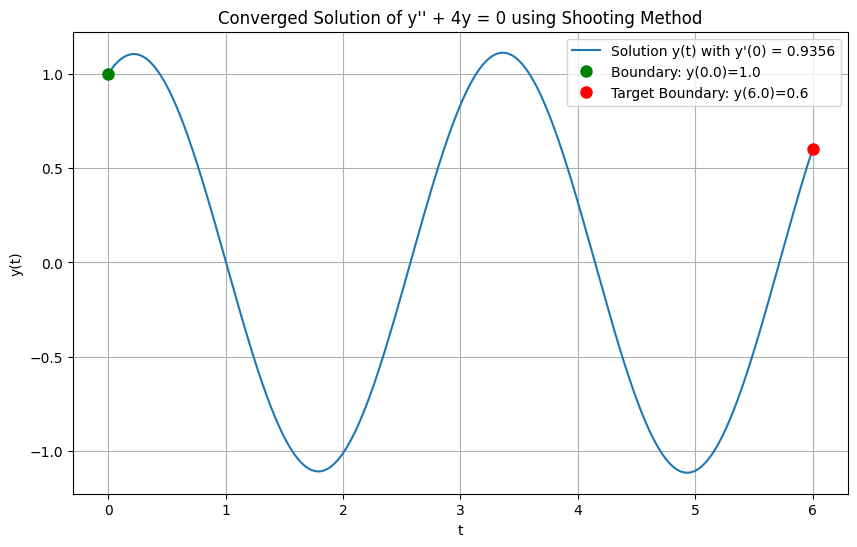

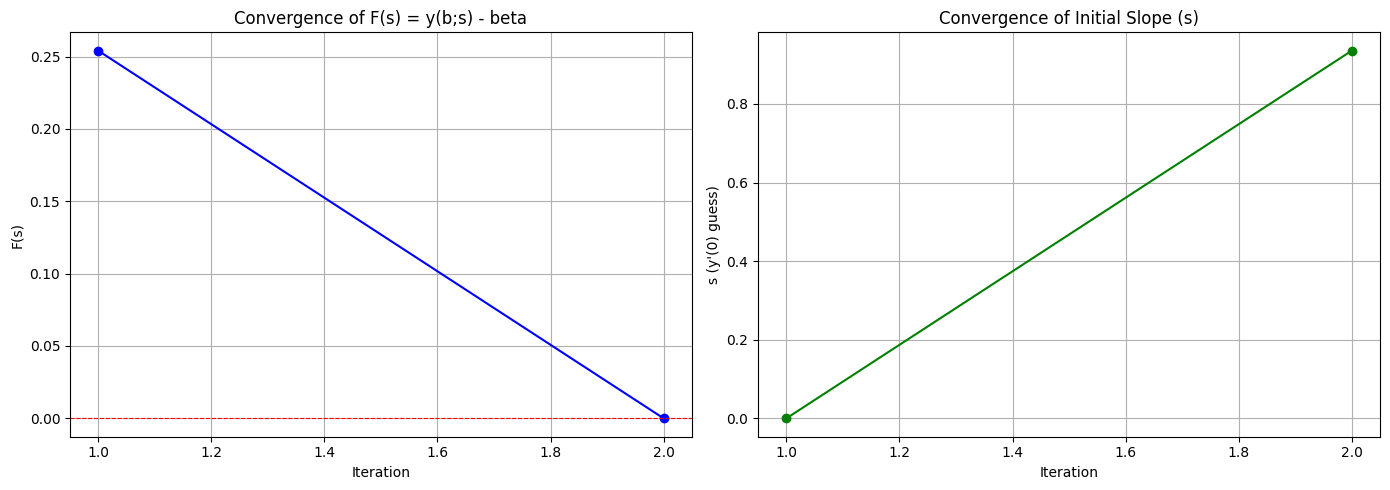

In [ ]:
# @title Shooting Method for y"+4y = 0 with y(0) = 1, y(6)=0.6
guess_y2 = 0 # @param {"type":"number","placeholder":"0"}
import numpy as np
import matplotlib.pyplot as plt

# --- 1. Define the Combined ODE System (y1, y2, z1, z2) ---
def combined_euler_step(y1, y2, z1, z2, h):
    # ODE for y
    dy1_dt = y2
    dy2_dt = -4 * y1

    # ODE for sensitivities (z = dy/ds)
    dz1_dt = z2
    dz2_dt = -4 * z1

    y1_new = y1 + dy1_dt * h
    y2_new = y2 + dy2_dt * h
    z1_new = z1 + dz1_dt * h
    z2_new = z2 + dz2_dt * h

    return y1_new, y2_new, z1_new, z2_new

# --- 2. Shooting Function (Solves IVP for a given initial_s) ---
def solve_bvp_shooting(initial_s, y1_a, t_start, t_end, h):
    # Initial conditions for y (main ODE)
    y1 = y1_a
    y2 = initial_s  # This is our 's' parameter

    # Initial conditions for z (sensitivities)
    z1 = 0.0  # z1(a) = dy1(a)/ds = d(alpha)/ds = 0
    z2 = 1.0  # z2(a) = dy2(a)/ds = ds/ds = 1

    n_steps = int((t_end - t_start) / h)

    # Store full trajectories for plotting the final solution
    t_values = np.linspace(t_start, t_end, n_steps + 1)
    y1_trajectory = np.zeros(n_steps + 1)
    y2_trajectory = np.zeros(n_steps + 1)

    y1_trajectory[0] = y1
    y2_trajectory[0] = y2

    # Integrate the combined system
    for i in range(n_steps):
        y1, y2, z1, z2 = combined_euler_step(y1, y2, z1, z2, h)
        y1_trajectory[i+1] = y1
        y2_trajectory[i+1] = y2

    # Return the values at the end point t_end (b)
    return y1, z1, y1_trajectory, t_values

# --- 3. Main Shooting Method with Newton's Iteration ---
def shooting_method_newton(y1_a, target_y_b, t_start, t_end, h, initial_guess_s, tol=1e-6, max_iter=100):
    s_k = initial_guess_s
    iterations = 0
    F_values = []
    s_values = []
    final_y1_trajectory = None
    final_t_values = None

    print(f"Starting Shooting Method (y(a)={y1_a}, y(b)={target_y_b})")

    for i in range(max_iter):
        iterations = i + 1
        y1_at_b, z1_at_b, current_y1_trajectory, t_values = solve_bvp_shooting(s_k, y1_a, t_start, t_end, h)

        F_sk = y1_at_b - target_y_b
        F_prime_sk = z1_at_b

        F_values.append(F_sk)
        s_values.append(s_k)

        print(f"Iter {iterations}: s_k = {s_k:.6f}, y1(b) = {y1_at_b:.6f}, F(s_k) = {F_sk:.6f}, F'(s_k) = {F_prime_sk:.6f}")

        if abs(F_sk) < tol:
            print(f"Converged in {iterations} iterations with s = {s_k:.6f}")
            final_y1_trajectory = current_y1_trajectory
            final_t_values = t_values
            break

        if F_prime_sk == 0:
            print("Warning: F'(s_k) is zero. Cannot proceed with Newton's method.")
            break

        s_k_plus_1 = s_k - F_sk / F_prime_sk
        s_k = s_k_plus_1
    else:
        print(f"Did not converge within {max_iter} iterations. Final s = {s_k:.6f}, F(s_k) = {F_sk:.6f}")
        final_y1_trajectory = current_y1_trajectory
        final_t_values = t_values

    return s_k, final_y1_trajectory, final_t_values, F_values, s_values

# --- Problem Parameters ---
y1_at_a = 1.0       # y(0) = 1
target_y_at_b = 0.6 # y(6) = 0.6
t_a = 0.0           # Start time
t_b = 6.0           # End time (where boundary condition is applied)
h = 0.001           # Step size
initial_s_guess = guess_y2 # Initial guess for y'(0)

# --- Run the Shooting Method ---
converged_s, solution_trajectory, t_solution, F_history, s_history = shooting_method_newton(
    y1_at_a, target_y_at_b, t_a, t_b, h, initial_s_guess
)

# --- Plotting Results ---

# Plot the converged solution
fig1 = plt.figure(figsize=(10, 6))
plt.plot(t_solution, solution_trajectory, label=f'Solution y(t) with y\'(0) = {converged_s:.4f}')
plt.plot(t_a, y1_at_a, 'go', markersize=8, label=f'Boundary: y({t_a})={y1_at_a}')
plt.plot(t_b, target_y_at_b, 'ro', markersize=8, label=f'Target Boundary: y({t_b})={target_y_at_b}')
plt.title("Converged Solution of y'' + 4y = 0 using Shooting Method")
plt.xlabel('t')
plt.ylabel('y(t)')
plt.legend()
plt.grid(True)
plt.show()

# Plot the convergence of F(s) and s
fig2, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(range(1, len(F_history) + 1), F_history, 'b-o')
axes[0].axhline(0, color='red', linestyle='--', linewidth=0.8)
axes[0].set_title('Convergence of F(s) = y(b;s) - beta')
axes[0].set_xlabel('Iteration')
axes[0].set_ylabel('F(s)')
axes[0].grid(True)

axes[1].plot(range(1, len(s_history) + 1), s_history, 'g-o')
axes[1].set_title('Convergence of Initial Slope (s)')
axes[1].set_xlabel('Iteration')
axes[1].set_ylabel('s (y\'(0) guess)')
axes[1].grid(True)

plt.tight_layout()
plt.show()


In this case you will see that the shooting method converges in about two iterations, almost independent of the initial guess.

## 🔗 Bridge to Week 10

This notebook demonstrated the power of the shooting method in addressing boundary value problems (BVPs), which are fundamentally different from initial value problems (IVPs) due to conditions imposed at multiple points (not just the initial values). We established that by treating the BVP as an IVP with an unknown initial condition, we can iteratively 'shoot' for the target boundary.

We then explored how Newton's method can be employed to systematically refine our initial guess for the missing condition, transforming the 'trial and error' approach into a robust, convergent algorithm. This involved deriving and integrating sensitivity equations alongside the primary ODEs to compute the derivative of the shooting function.

While the shooting method offers a powerful framework for solving BVPs by leveraging IVP solvers, the balance between an accurate initial guess, step size, and the potential for non-convergence or multiple solutions remains a critical consideration.

In Week 10, we will introduce and alternative method of solving boundary value problems, before looking at how ODEs methods are connected to Machine Learning, and how ODEs and Machine Learning Methods can be combined.

#🤖 AI Acknowledgment

MS CoPilot v25.6.440430001 was used to proof read this notebook and provided the code for the explicit Euler method initial value implementation and the code for the shooting method based on authors prompt. These are modified to include the code input forms to help enable efficient experimentation in terms of chosen guesses for $y_2(0)$.